## Import libraries

In [ ]:
import sys 
sys.path.append("../")

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Visualization settings
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## Load the dataset

In [ ]:
from src.config import RAW_DATA_PATH

df = pd.read_csv(RAW_DATA_PATH)
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


In [31]:
df.isna().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe().round(2)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.00,614.00,592.00,600.00,564.00
mean,5403.46,1621.25,146.41,342.00,0.84
std,6109.04,2926.25,85.59,65.12,0.36
min,150.00,0.00,9.00,12.00,0.00
25%,2877.50,0.00,100.00,360.00,1.00
50%,3812.50,1188.50,128.00,360.00,1.00
75%,5795.00,2297.25,168.00,360.00,1.00
max,81000.00,41667.00,700.00,480.00,1.00


## EDA

array([[<Axes: title={'center': 'ApplicantIncome'}>,
        <Axes: title={'center': 'CoapplicantIncome'}>],
       [<Axes: title={'center': 'LoanAmount'}>,
        <Axes: title={'center': 'Loan_Amount_Term'}>],
       [<Axes: title={'center': 'Credit_History'}>, <Axes: >]],
      dtype=object)

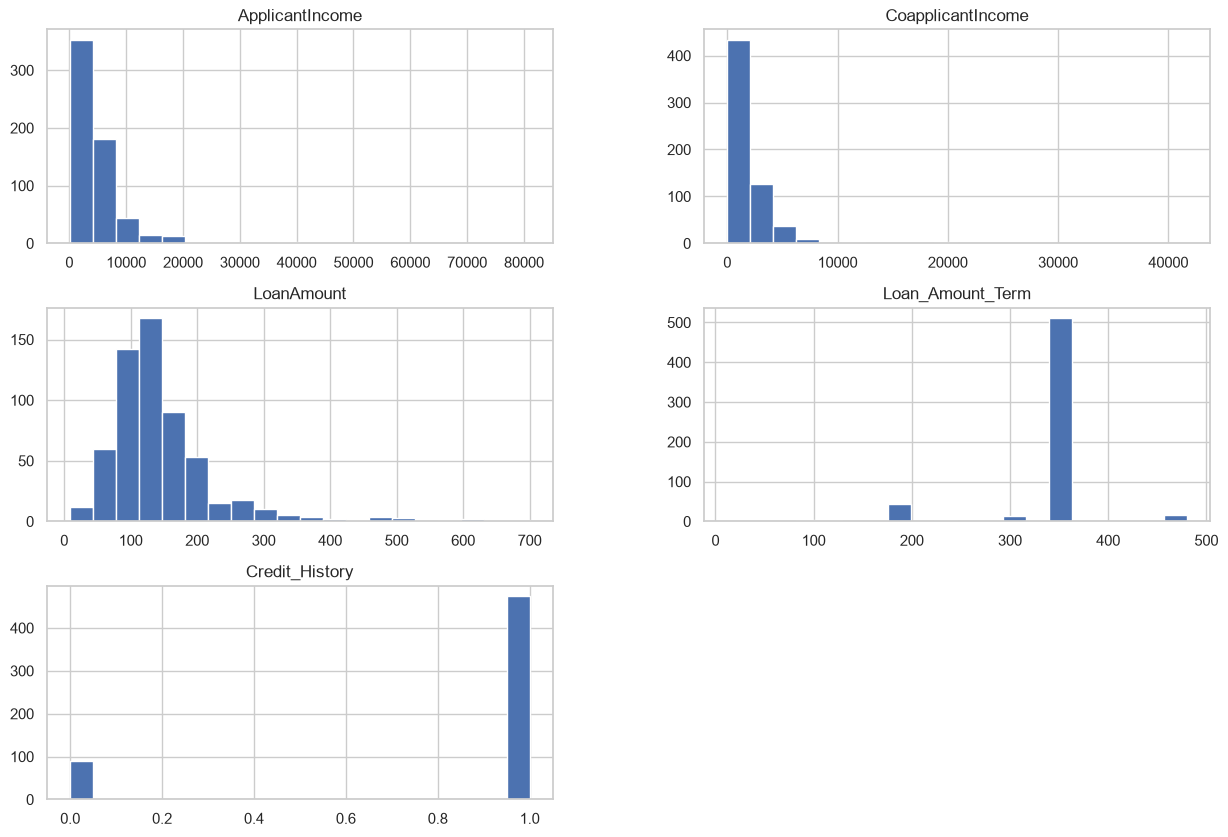

In [10]:
# Distribution plot for numerical features
df.hist(bins=20, figsize=(15, 10))

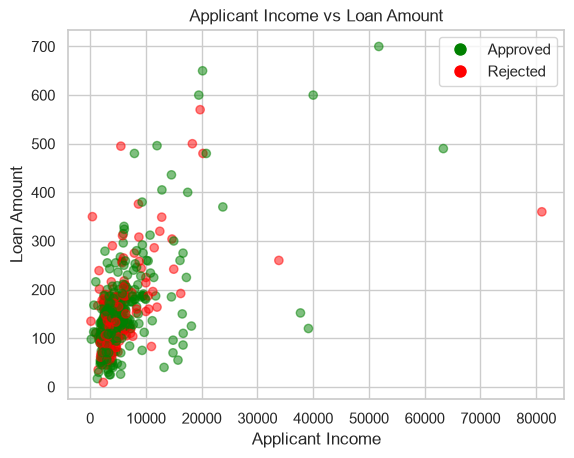

In [44]:
plt.scatter(df['ApplicantIncome'], df['LoanAmount'], 
            c=df['Loan_Status'].map({'Y': 'green', 'N': 'red'}), alpha=0.5)
plt.title('Applicant Income vs Loan Amount')
plt.xlabel('Applicant Income')
plt.ylabel('Loan Amount')
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', label='Approved',
                          markerfacecolor='green', markersize=10),
           plt.Line2D([0], [0], marker='o', color='w', label='Rejected',
                          markerfacecolor='red', markersize=10)])

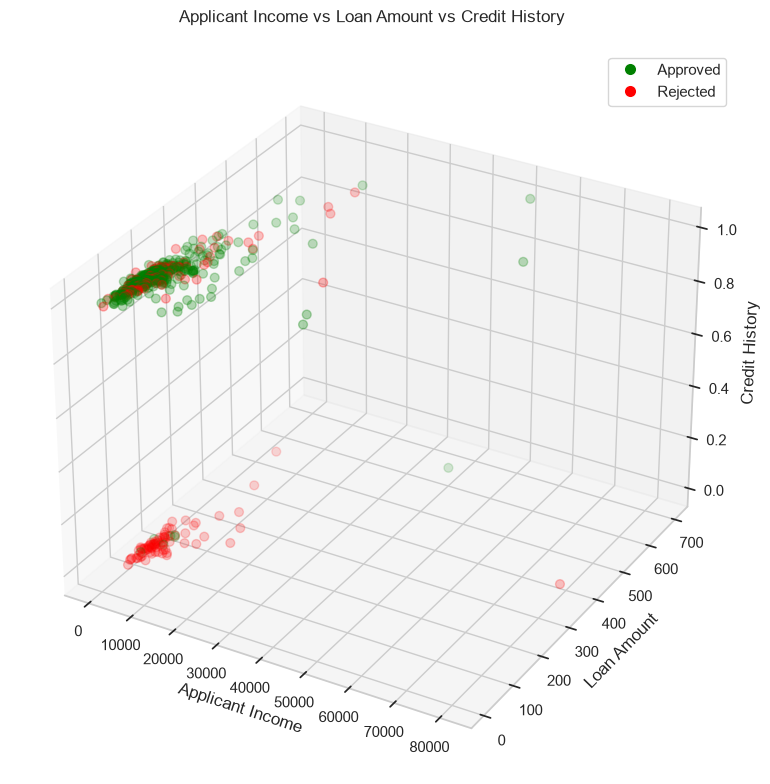

In [45]:
from mpl_toolkits.mplot3d import Axes3D  # Registers 3D projection
from matplotlib.lines import Line2D

# Select the columns required for the plot
plot_df = df[
    [
        "ApplicantIncome",
        "LoanAmount",
        "Credit_History",
        "Loan_Status",
    ]
].dropna().copy()

# Map loan status to colors
colors = plot_df["Loan_Status"].map({
    "Y": "green",
    "N": "red",
})

# Create a 3D figure
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    plot_df["ApplicantIncome"],
    plot_df["LoanAmount"],
    plot_df["Credit_History"],
    c=colors,
    alpha=0.55,
    s=40,
)

ax.set_title(
    "Applicant Income vs Loan Amount vs Credit History",
    pad=20,
)
ax.set_xlabel("Applicant Income")
ax.set_ylabel("Loan Amount")
ax.set_zlabel("Credit History")

# Legend for the target variable
legend_handles = [
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Approved",
        markerfacecolor="green",
        markersize=9,
    ),
    Line2D(
        [0], [0],
        marker="o",
        color="w",
        label="Rejected",
        markerfacecolor="red",
        markersize=9,
    ),
]

ax.legend(handles=legend_handles)
plt.tight_layout()
plt.show()

### Breakdown by `Credit_History`

In [57]:
# copy raw data to a new dataframe for preprocessing
states_by_CH = df.copy()
states_by_CH["Loan_Status"] = states_by_CH["Loan_Status"].map({"Y": 1, "N": 0})

# Group by Credit History and count the number of approved and rejected loans
# count approved loans
states_by_CH = states_by_CH.groupby("Credit_History")[["Loan_Status"]].sum()
states_by_CH = states_by_CH.rename(columns={"Loan_Status": "Approved_Loans"})

# count total loans
states_by_CH["Total_Loans"] = df.groupby("Credit_History")["Loan_Status"].count()

# calculate rejected loans
states_by_CH["Rejected_Loans"] = states_by_CH["Total_Loans"] - states_by_CH["Approved_Loans"]

# arrange the columns for better readability
states_by_CH = states_by_CH[["Approved_Loans", "Rejected_Loans", "Total_Loans"]]
states_by_CH


,Approved_Loans,Rejected_Loans,Total_Loans
Credit_History,,,
0.0,7,82,89
1.0,378,97,475


In [64]:
# Calculate the approval rate and rejection rate for each credit history category
states_by_CH["Approval_Rate"] = ((states_by_CH["Approved_Loans"] / states_by_CH["Total_Loans"]) * 100).round(2)
states_by_CH["Rejection_Rate"] = ((states_by_CH["Rejected_Loans"] / states_by_CH["Total_Loans"]) * 100).round(2)
states_by_CH

,Approved_Loans,Rejected_Loans,Total_Loans,Approval_Rate,Rejection_Rate
Credit_History,,,,,
0.0,7,82,89,7.87,92.13
1.0,378,97,475,79.58,20.42


### Breakdown by Dependents

In [69]:
# identify the relation between number of dependents and loanAmount
dependents_loan_amount = df.groupby('Dependents')['LoanAmount'].mean().round(2)
dependents_loan_amount


Dependents
0     135.89
1     158.62
2     150.22
3+    190.90
Name: LoanAmount, dtype: float64

Text(0, 0.5, 'Average Loan Amount')

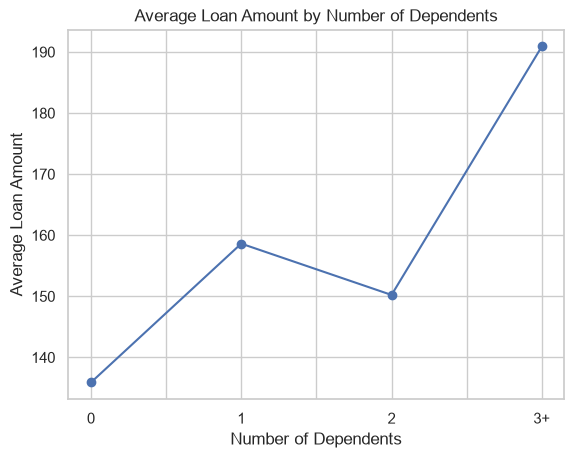

In [70]:
dependents_loan_amount.plot(kind='line', marker='o')
plt.title('Average Loan Amount by Number of Dependents')
plt.xlabel('Number of Dependents')
plt.ylabel('Average Loan Amount')

In [68]:
grouped = df.groupby('Dependents')['Loan_Status'].value_counts(normalize=True).unstack()
grouped.round(2)

Loan_Status,N,Y
Dependents,,
0,0.31,0.69
1,0.35,0.65
2,0.25,0.75
3+,0.35,0.65


### Gender Distribution

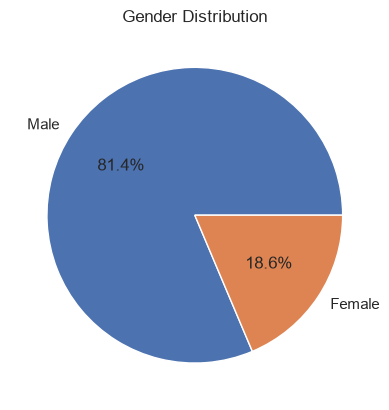

In [13]:
# visualize Gender distribution using a pie chart
gender_counts = df['Gender'].value_counts()
plt.pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%')
plt.title('Gender Distribution')
plt.show()

### Target distribution

<Axes: xlabel='Loan_Status'>

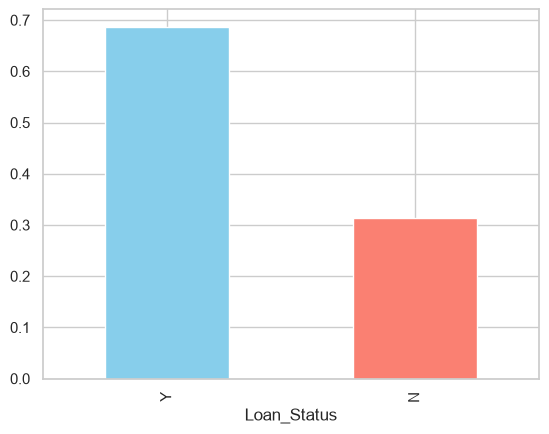

In [ ]:
# Visualize the distribution of Loan_Status (target variable)
df['Loan_Status'].value_counts(normalize=True).plot(kind='bar', color=['skyblue', 'salmon'])

The dataset has historically contained more approved than rejected loans.